# Structural Break Tests in Time Series: Practice on Financial Data

**Course:** Data Analysis in Finance
**Paper:** Muthuramu P., Uma Maheswari T. (2019). *Tests for Structural Breaks in Time Series Analysis: A Review of Recent Development.* Shanlax International Journal of Economics, 7(4), 66–79. DOI: 10.34293/economics.v7i4.628
**Authors of this work:** Pikuleva, Tolmacheva, Beznosenkova, Tsurkan

The paper reviews three generations of structural break tests:

| Generation | What is unknown | Tests in the paper | Section of this notebook |
|---|---|---|---|
| 1 | nothing: the break date is given in advance | Chow (1960), Chow predictive test | Section 2 |
| 2 | the date of **one** break | Quandt (1960) QLR, Andrews (1993) sup-F, Andrews–Ploberger (1994), CUSUM / CUSUMSQ (Brown–Durbin–Evans, 1975), OLS-CUSUM (Ploberger–Krämer, 1992) | Sections 3–4 |
| 3 | the **number and dates** of breaks | Bai–Perron (1998, 2003): dynamic programming, sup-F(k), UDmax/WDmax, sup-F(l+1\|l), BIC/LWZ | Sections 5–6 |

Everything is implemented **from scratch** with numpy/scipy in the `src/structbreaks` package (statistics, recursive residuals,
dynamic programming, simulation of critical values), so that the inner workings of each method are visible rather than hidden behind a library call.

**Data** (real, from open sources, stored in `data/raw/`):
1. `nile.csv` — Nile river flow 1871–1970 (benchmark example used to validate the implementation);
2. `capm_monthly_1960_2002.csv` — monthly excess returns of industry portfolios and the market (Kenneth French data library via the R package `Ecdat`, Verbeek 2004) → **stability of CAPM beta**;
3. `usmacro_quarterly_1950_2000.csv` — quarterly US macro data (Greene 2003, R package `AER`), ex-post real rate = T-bill − inflation → **real interest rate regimes** — exactly the Bai–Perron example discussed in the paper;
4. `sp500_daily_1950_2018.csv` — daily S&P 500 prices (R package `openintro`) → **volatility regimes**.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve() / "src"))
warnings.filterwarnings("ignore")

from structbreaks import (bai_perron, break_confidence_intervals, chow_dummy_wald, chow_predictive,
                          chow_test, cusum_test, cusumsq_test, dynamic_programming, ols,
                          ols_cusum_test, regime_estimates, ssr_matrix, sup_f_test)
from structbreaks.single_break import andrews_critical_values
from structbreaks.critical_values import BP2003_PUBLISHED_5PCT, bp_critical_values
from structbreaks import plotting as P

P.set_style()
DATA = Path("../data/raw")
RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)
pd.set_option("display.width", 140)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5

## 1. Validating the implementation on a benchmark (the Nile)

The Nile flow series is the standard test for any implementation: construction of the Aswan dam began in 1898 and the mean flow dropped.
The "correct" answers for this series are known from the R package `strucchange` (Zeileis et al., 2002, cited in the paper):
sup-F = 75.93, break date 1898. If our functions reproduce this, they can be trusted on financial data.

Quandt-Andrews (trim=0.15, cov=ols, q=1):
  sup-F =   75.930  p = 0.0000
  exp-W =   33.759  p = 0.0000   (Andrews-Ploberger)
  ave-W =   21.215  p = 0.0000
  estimated break date (last observation of regime 1): 1898

Bai–Perron: selected number of breaks: {'sequential': 1, 'BIC': 1, 'LWZ': 1, 'UDmax/WDmax': 'breaks present'}
Dates (last year of regime 1): [np.int64(1898)]

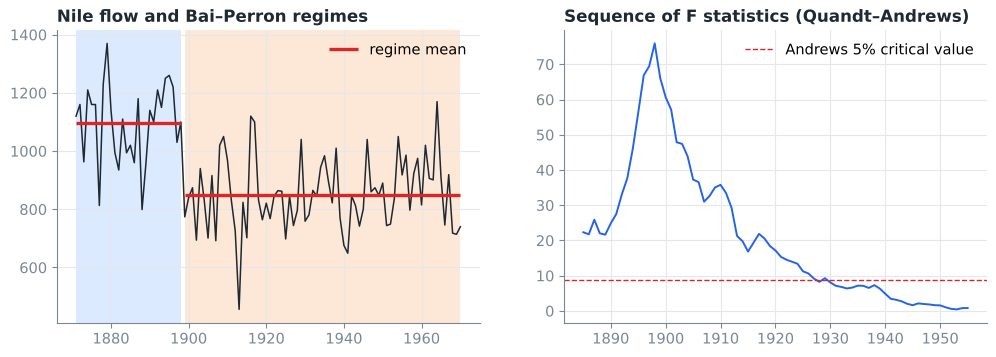

In [2]:
nile = pd.read_csv(DATA / "nile.csv")
y_nile = nile["value"].values
yrs = nile["time"].values
ones = np.ones((len(y_nile), 1))

qa = sup_f_test(y_nile, ones)
print(qa.summary(yrs))
bp_nile = bai_perron(y_nile, trim=0.15, M=5, index=yrs)
print("\nBai–Perron: selected number of breaks:", bp_nile.selected)
print("Dates (last year of regime 1):", bp_nile.break_dates(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(yrs, y_nile, color=P.INK, lw=1.1)
means, _, _ = regime_estimates(y_nile, None, bp_nile.ends[1])
P.shade_regimes(ax[0], yrs, bp_nile.ends[1])
P.plot_regime_means(ax[0], yrs, y_nile, bp_nile.ends[1], means[:, 0])
ax[0].set_title("Nile flow and Bai–Perron regimes"); ax[0].legend()
ax[1].plot(yrs[qa.candidates - 1], qa.F, color=P.BLUE)
cv = andrews_critical_values(1, 0.15)["sup"]
ax[1].axhline(cv[0.05], color=P.RED, ls="--", lw=1, label="Andrews 5% critical value")
ax[1].set_title("Sequence of F statistics (Quandt–Andrews)"); ax[1].legend()
P.savefig(fig, "00_nile_validation")

**Conclusion:** sup-F = 75.93 and the 1898 date match the benchmark — the implementation is correct (this is also checked in `tests/`).

Next, we compare our **simulated critical values** with the published tables of Andrews (1993) and Bai–Perron (2003):

In [3]:
print("Andrews (1993), q=1, π0=0.15:  published 5% = 8.68, 1% = 12.16")
print("  our simulation:", {k: round(v, 2) for k, v in andrews_critical_values(1, 0.15)["sup"].items()})
mine = bp_critical_values(1, 0.15, 5)
pub = BP2003_PUBLISHED_5PCT[1]
print("\nBai–Perron, q=1, ε=0.15, 5%:")
print("  sup-F(k)  simulated:", [round(mine['supF'][k], 2) for k in range(1, 6)], " | BP:", pub["supF"])
print(f"  UDmax     simulated: {mine['UDmax']:.2f} | BP: {pub['UDmax']}")
print(f"  WDmax     simulated: {mine['WDmax']:.2f} | BP: {pub['WDmax']}")
print("  F(l+1|l)  simulated:", [round(mine['seq'][l], 2) for l in range(5)], " | BP:", pub["seq"])
m2 = bp_critical_values(2, 0.15, 5)
print("\nq=2: sup-F(1) from the DP simulation (T=500):", round(m2["supF"][1], 2),
      "| Brownian-bridge asymptotics:", round(andrews_critical_values(2, 0.15)["sup"][0.05], 2))

Andrews (1993), q=1, π0=0.15:  published 5% = 8.68, 1% = 12.16
  our simulation: {0.1: 7.1, 0.05: 8.7, 0.01: 12.24}

Bai–Perron, q=1, ε=0.15, 5%:
  sup-F(k)  simulated: [8.43, 7.15, 5.92, 4.99, 3.85]  | BP: [8.58, 7.22, 5.96, 4.99, 3.91]
  UDmax     simulated: 8.76 | BP: 8.88
  WDmax     simulated: 9.80 | BP: 9.91
  F(l+1|l)  simulated: [8.43, 9.85, 10.77, 11.65, 12.26]  | BP: [8.58, 10.13, 11.14, 11.83, 12.25]

q=2: sup-F(1) from the DP simulation (T=500): 12.04 | Brownian-bridge asymptotics: 11.6

For q = 1 the differences are within Monte Carlo error (±0.1–0.3): we have reproduced the tables the paper relies on. For q = 2 the finite-sample simulation (T = 500, random regressor) gives values about 0.4 above the asymptotic ones — the test is slightly conservative, which is acceptable for our purposes. More precise values can be obtained with `scripts/simulate_critical_values.py` and a larger T.

---
## 2. Break at a known date: the Chow test and CAPM beta

**Financial setting.** The beta of the food industry (a defensive sector) from the market model
$$r^{food}_t - r^f_t = \alpha + \beta\,(r^m_t - r^f_t) + \varepsilon_t,$$
monthly data, 1960–2002. For portfolio management it matters whether beta is constant: if not, hedge ratios and the cost of capital estimated on the full sample are a mixture of different regimes.

The Chow test requires the date to be **chosen in advance**. As the paper suggests ("exogenous events: oil shocks, crises…"), we take historical candidates:
the oil shock (Oct 1973), the Fed policy change (Oct 1979), the 1987 crash (Oct 1987), and the Asian crisis (Jul 1997).

In [4]:
capm = pd.read_csv(DATA / "capm_monthly_1960_2002.csv")
capm.index = pd.period_range("1960-01", periods=len(capm), freq="M")
dates_m = capm.index.to_timestamp()
y_food = capm["rfood"].values
X_mkt = np.column_stack([np.ones(len(capm)), capm["rmrf"].values])
T_c = len(y_food)

full = ols(y_food, X_mkt)
print(f"Full sample: alpha = {full.beta[0]:.3f}, beta = {full.beta[1]:.3f}, T = {T_c}\n")

events = {"Oil shock": "1973-10", "Volcker policy": "1979-10",
          "1987 crash": "1987-10", "Asian crisis": "1997-07"}
rows = []
for name, d in events.items():
    n1 = capm.index.get_loc(pd.Period(d, "M")) + 1      # the event month is the last month of regime 1
    c, w = chow_test(y_food, X_mkt, n1), chow_dummy_wald(y_food, X_mkt, n1)
    b1, b2 = ols(y_food[:n1], X_mkt[:n1]).beta[1], ols(y_food[n1:], X_mkt[n1:]).beta[1]
    rows.append([name, d, round(b1, 3), round(b2, 3), round(c.statistic, 2), round(c.pvalue, 4),
                 round(w.statistic, 2), round(w.pvalue, 4)])
chow_tab = pd.DataFrame(rows, columns=["event", "date", "β before", "β after", "Chow F", "p (F)",
                                       "Wald/2 (HAC)", "p (HAC)"])
print(chow_tab.to_string(index=False))
chow_tab.to_csv(RESULTS / "chow_capm_food.csv", index=False)

Full sample: alpha = 0.339, beta = 0.783, T = 516

         event    date  β before  β after  Chow F  p (F)  Wald/2 (HAC)  p (HAC)
     Oil shock 1973-10     0.897    0.749    2.54 0.0801          1.72   0.1795
Volcker policy 1979-10     0.963    0.647   17.64 0.0000          6.65   0.0013
    1987 crash 1987-10     0.882    0.582   13.11 0.0000          2.91   0.0545
  Asian crisis 1997-07     0.889    0.331   33.48 0.0000          6.34   0.0018

**What we see.**
* The classical Chow F-test "finds" a break at three of the four chosen dates, and the estimated "after" beta is different every time. This is exactly the problem the paper describes with reference to Hansen (2001): if the true break is elsewhere, a test at an arbitrary date still rejects H0 and creates false confidence about the date.
* The classical F-test assumes **equal error variance** in both regimes. The paper (Toyoda 1974; Schmidt & Sickles 1977) warns that heteroskedasticity distorts the size of the test. Return variance clearly changes over time, so the HAC (Newey–West) version gives noticeably more cautious p-values.

We also show the **predictive** Chow test (the second case in the paper, $n_2 < k$): do the last months of the sample "fit" the model estimated on the earlier data?

In [5]:
for n2 in (2, 12):
    print(f"Predictive test, last {n2} months:", chow_predictive(y_food, X_mkt, T_c - n2))

Predictive test, last 2 months: Chow predictive test: stat=2.937, p-value=0.0539, df=(2, 512)
Predictive test, last 12 months: Chow predictive test: stat=1.440, p-value=0.1437, df=(12, 502)

---
## 3. Break at an unknown date: Quandt–Andrews (sup-F)

Quandt (1960) proposed computing the Chow F statistic at **every** possible date and taking the maximum (QLR). The distribution of the maximum is non-standard — Andrews (1993) derived and tabulated it; we trim $\pi_0 = 15\%$ at each end (the paper's "trimming 15 percent").
Andrews & Ploberger (1994) proposed optimal averaged versions: exp-W and ave-W.

Quandt-Andrews (trim=0.15, cov=ols, q=2):
  sup-F =   31.258  p = 0.0000
  exp-W =   28.193  p = 0.0000   (Andrews-Ploberger)
  ave-W =   26.447  p = 0.0000
  estimated break date (last observation of regime 1): 1996-07

Quandt-Andrews (trim=0.15, cov=hac, q=2):
  sup-F =    7.076  p = 0.0182
  exp-W =    5.420  p = 0.0065   (Andrews-Ploberger)
  ave-W =    8.475  p = 0.0032
  estimated break date (last observation of regime 1): 1991-12

5% critical value of sup-F (q=2, F scale = Wald/2): 5.80

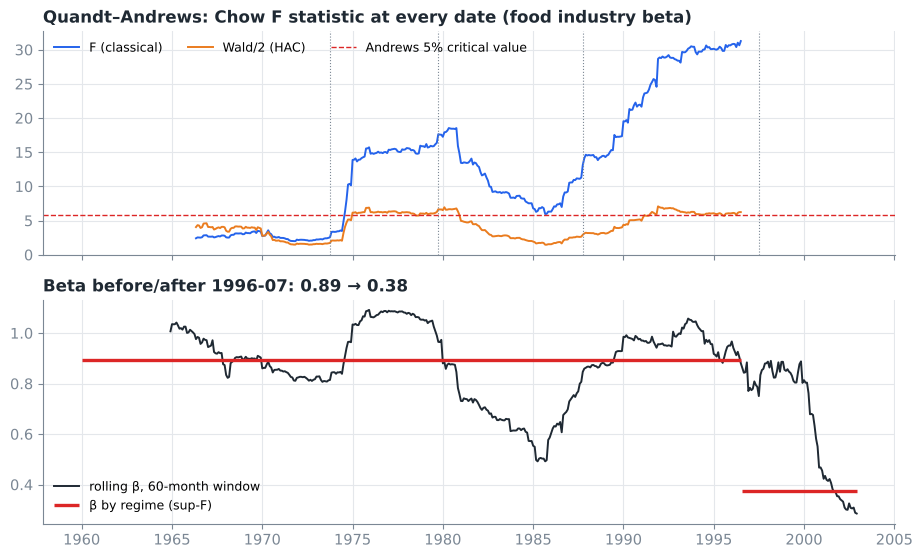

In [6]:
qa_ols = sup_f_test(y_food, X_mkt, trim=0.15, cov="ols")
qa_hac = sup_f_test(y_food, X_mkt, trim=0.15, cov="hac")
print(qa_ols.summary(capm.index.astype(str)))
print()
print(qa_hac.summary(capm.index.astype(str)))
cv2 = andrews_critical_values(2, 0.15)["sup"]
print(f"\n5% critical value of sup-F (q=2, F scale = Wald/2): {cv2[0.05] / 2:.2f}")

# rolling beta (5 years) — for intuition
win = 60
roll_beta = pd.Series([ols(y_food[i - win:i], X_mkt[i - win:i]).beta[1] for i in range(win, T_c + 1)],
                      index=dates_m[win - 1:])

fig, ax = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
x_c = dates_m[qa_ols.candidates - 1]
ax[0].plot(x_c, qa_ols.F, color=P.BLUE, label="F (classical)")
ax[0].plot(x_c, qa_hac.F, color=P.ORANGE, label="Wald/2 (HAC)")
ax[0].axhline(cv2[0.05] / 2, color=P.RED, ls="--", lw=1, label="Andrews 5% critical value")
for d in events.values():
    ax[0].axvline(pd.Period(d, "M").to_timestamp(), color=P.MUTED, lw=0.8, ls=":")
ax[0].set_title("Quandt–Andrews: Chow F statistic at every date (food industry beta)")
ax[0].legend(ncol=3, fontsize=9)
ax[1].plot(roll_beta.index, roll_beta.values, color=P.INK, label="rolling β, 60-month window")
b_idx = qa_ols.argmax
b_pre, b_post = ols(y_food[:b_idx], X_mkt[:b_idx]).beta[1], ols(y_food[b_idx:], X_mkt[b_idx:]).beta[1]
ax[1].hlines(b_pre, dates_m[0], dates_m[b_idx - 1], color=P.RED, lw=2.4, label="β by regime (sup-F)")
ax[1].hlines(b_post, dates_m[b_idx], dates_m[-1], color=P.RED, lw=2.4)
ax[1].set_title(f"Beta before/after {capm.index[b_idx - 1]}: {b_pre:.2f} → {b_post:.2f}")
ax[1].legend(fontsize=9)
P.savefig(fig, "02_capm_supF")

**Interpretation.** The F sequence peaks in mid-1996: during the dot-com bubble defensive industries "decoupled" from the market, and the food industry beta fell from about 0.9 to 0.4. Note that the HAC version is much lower than the classical one and its peak shifts — heteroskedasticity of returns really does affect the conclusion (the paper mentions this but does not show it).

---
## 4. CUSUM tests (Brown, Durbin & Evans, 1975; Ploberger & Krämer, 1992)

CUSUM accumulates **recursive residuals** (one-step-ahead forecast errors); after a break they tend to have the same sign and the path crosses the linear boundaries. CUSUM of squares reacts to a change in **variance**. OLS-CUSUM uses ordinary OLS residuals.

CUSUM (Brown-Durbin-Evans) (alpha=0.05): H0 not rejected 
CUSUM of squares (alpha=0.05): H0 (stability) REJECTED, first crossing at t=66 → 1965-07
OLS-CUSUM (Ploberger-Krämer) (alpha=0.05): H0 not rejected 

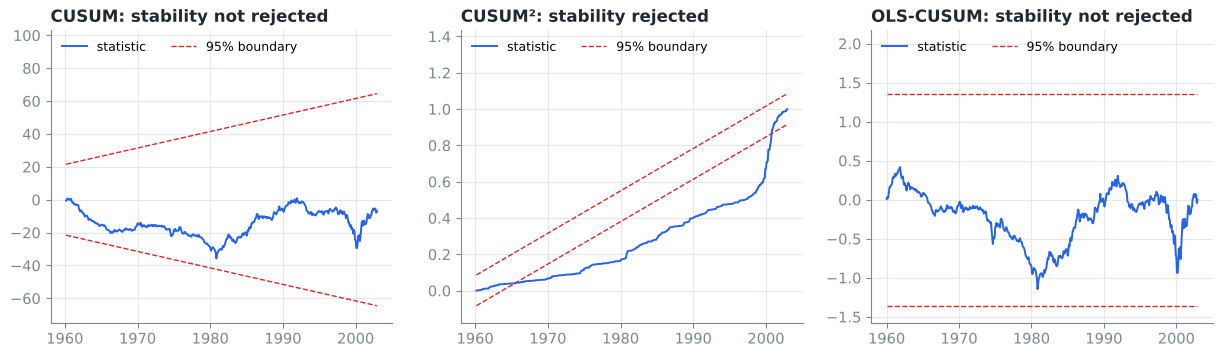

In [7]:
res_cusum = cusum_test(y_food, X_mkt)
res_cusumsq = cusumsq_test(y_food, X_mkt)
res_olscusum = ols_cusum_test(y_food, X_mkt)
for r in (res_cusum, res_cusumsq, res_olscusum):
    fc = r.first_crossing
    print(r, "" if fc is None else f"→ {capm.index[fc]}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
P.plot_cusum(ax[0], res_cusum, dates_m, "CUSUM")
P.plot_cusum(ax[1], res_cusumsq, dates_m, "CUSUM²")
P.plot_cusum(ax[2], res_olscusum, dates_m, "OLS-CUSUM")
for a in ax:
    a.title.set_fontsize(10)
P.savefig(fig, "03_capm_cusum")

**Key observation.** CUSUM does not detect the beta shift, although sup-F finds it with confidence. This is a known result of Krämer, Ploberger & Alt (1988) that the paper mentions only in passing ("the CUSUM test aims to detect precise movements…"): CUSUM has power only against shifts that are **not orthogonal to the mean of the regressors**. The market excess return has a mean close to zero, so a change in beta is almost "invisible" to CUSUM. CUSUM² does react — but to the change in residual variance (the volatile 1970s and late 1990s), not to beta. The lesson: CUSUM tests are a diagnostic, not a dating tool. The Monte Carlo study in Section 7 confirms this.

---
## 5. Multiple breaks: Bai–Perron and the real interest rate

### 5.1. How dynamic programming works (Figure 1 and Table 1 of the paper)

Enumerating all partitions into $m+1$ segments costs $O(T^m)$. Bai & Perron (2003) observe that it is enough to compute the SSR of each admissible segment $[i, j]$ once (at most $T(T+1)/2$ of them) and then solve the recursion
$$SSR(\{T_{m}\}) = \min_{mh \le j \le T-h}\big[SSR(\{T_{m-1}\}_{1..j}) + SSR(j+1, T)\big].$$
We reproduce the triangular matrix of Figure 1 ($T=25$, $h=5$, $m=2$) and check the arithmetic of Table 1.

Our classification, T=25, h=5, m=2: {'xa': 94, 'xb': 75, 'xc': 34, '*': 122}   total: 325
T=25, h=5, m=2: Table 1 formulas → {'total': 325, 'xa': 94, 'xb': 75, 'xc': 34, 'acceptable': 122}
    direct count using the Figure 1 rule → 122;  printed in the paper → 122
T=53, h=8, m=5: Table 1 formulas → {'total': 1431, 'xa': 350, 'xb': 960, 'xc': 14, 'acceptable': 107}
    direct count using the Figure 1 rule → 111;  printed in the paper → 117

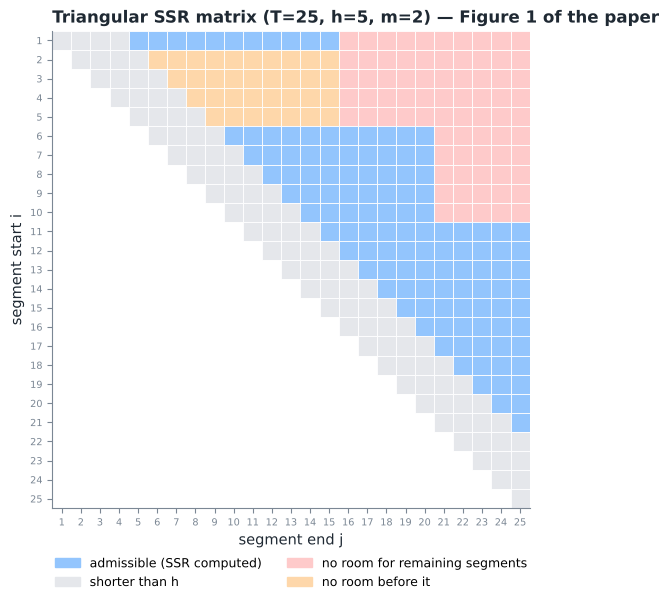

In [8]:
def triangular_matrix(T, h, m):
    """Classification of segments [i, j] following Bai & Perron (2003), as in Figure 1 of the paper."""
    M = np.full((T, T), "", dtype=object)
    for i in range(1, T + 1):
        k = (i - 1) // h                      # how many segments of length ≥ h can precede it
        last_end = T - max(m - k, 0) * h      # (m - k) more segments must fit after it
        for j in range(i, T + 1):
            if j - i + 1 < h:
                M[i - 1, j - 1] = "xa"        # shorter than the minimum length h
            elif j > last_end:
                M[i - 1, j - 1] = "xb"        # no room left for the remaining segments
            elif 1 < i <= h:
                M[i - 1, j - 1] = "xc"        # no room for a segment of length h before it
            else:
                M[i - 1, j - 1] = "*"         # admissible segment — its SSR is computed
    return M

Mtri = triangular_matrix(25, 5, 2)
counts = {k: int((Mtri == k).sum()) for k in ["xa", "xb", "xc", "*"]}
print("Our classification, T=25, h=5, m=2:", counts, "  total:", 25 * 26 // 2)

def table1_formulas(T, h, m):
    total = T * (T + 1) // 2
    xa = (h - 1) * T - (h - 2) * (h - 1) // 2
    xb = h * h * m * (m + 1) // 2
    xc = T * (h - 1) - m * h * (h - 1) - (h - 1) ** 2 - h * (h - 1) // 2
    return dict(total=total, xa=xa, xb=xb, xc=xc, acceptable=total - xa - xb - xc)

for T_, h_, m_, paper in [(25, 5, 2, 122), (53, 8, 5, 117)]:
    f = table1_formulas(T_, h_, m_)
    direct = int((triangular_matrix(T_, h_, m_) == "*").sum())
    print(f"T={T_}, h={h_}, m={m_}: Table 1 formulas → {f}\n"
          f"    direct count using the Figure 1 rule → {direct};  printed in the paper → {paper}")

fig, ax = plt.subplots(figsize=(7.2, 6.2))
colors = {"xa": "#e5e7eb", "xb": "#fecaca", "xc": "#fed7aa", "*": "#93c5fd", "": "white"}
for i in range(25):
    for j in range(25):
        ax.add_patch(plt.Rectangle((j, 24 - i), 1, 1, color=colors[Mtri[i, j]], ec="white", lw=0.6))
ax.set_xlim(0, 25); ax.set_ylim(0, 25); ax.set_aspect("equal"); ax.grid(False)
ax.set_xticks(np.arange(25) + 0.5, np.arange(1, 26), fontsize=7)
ax.set_yticks(np.arange(25) + 0.5, np.arange(25, 0, -1), fontsize=7)
ax.set_xlabel("segment end j"); ax.set_ylabel("segment start i")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=colors[k], label=l) for k, l in
                   [("*", "admissible (SSR computed)"), ("xa", "shorter than h"),
                    ("xb", "no room for remaining segments"), ("xc", "no room before it")]],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9)
ax.set_title("Triangular SSR matrix (T=25, h=5, m=2) — Figure 1 of the paper")
P.savefig(fig, "04_triangular_matrix")

For $T=25$ the formulas and the picture agree with the paper (122 admissible segments).
The second column of Table 1 ($T=53$, $h=8$, $m=5$), however, contains **arithmetic errors**: $5\cdot8\cdot7 = 280$, not 270, so the formula gives $xc = 14$, not 24; and even with the printed numbers $1431-350-960-24 = 97$, not 117. The paper's own formulas give **107**, while a direct count using the Figure 1 rule gives **111** (the formulas for $xb$ and $xc$ are only an approximation for large $m$, because the "no room" regions overlap). The printed 117 cannot be obtained in any way. A small point, but a good example of why the calculations in a review paper are worth reproducing in code.

### 5.2. The US real interest rate (the paper's example)

The paper recounts the empirical example of Bai & Perron: the US ex-post real interest rate, quarterly 1961:1–1986:3, a mean-shift model with up to 5 segments; two breaks are found — **1972:3 and 1980:3**. We repeat this on the Greene (2003) data. The errors are autocorrelated and probably heteroskedastic, so we use the HAC version of the tests (cov="hac"), as Bai–Perron do.

In [9]:
macro = pd.read_csv(DATA / "usmacro_quarterly_1950_2000.csv")
macro.index = pd.period_range("1950Q1", periods=len(macro), freq="Q")
rr = macro["interest"].dropna()
rr_bp = rr["1961Q1":"1986Q3"]
y_rr = rr_bp.values
q_idx = rr_bp.index.astype(str)

bp_rr = bai_perron(y_rr, trim=0.15, M=5, cov="hac", index=q_idx)
print(bp_rr.summary())

Bai-Perron: T=103, q=1, h=15 (trim=0.15), M=5, cov=hac

 k |  sup-F(k) | 5% crit. | break date(s) (global SSR minimum)
---+-----------+----------+-----------------------------------
 1 |    88.80* |     8.43 | ['1980Q3']
 2 |    82.97* |     7.15 | ['1972Q4', '1980Q2']
 3 |    61.44* |     5.92 | ['1967Q1', '1972Q4', '1980Q2']
 4 |    45.55* |     4.99 | ['1967Q1', '1972Q4', '1976Q3', '1980Q2']
 5 |    34.52* |     3.85 | ['1965Q1', '1968Q4', '1972Q4', '1976Q3', '1980Q2']

UDmax =   88.80  (5% crit. 8.76)  *
WDmax =   97.80  (5% crit. 9.80)  *

Sequential test sup-F(l+1|l):
  F(1|0) =    49.84* (5% crit. 8.43)
  F(2|1) =    33.00* (5% crit. 9.85)
  F(3|2) =     3.99  (5% crit. 10.77)
  F(4|3) =     0.07  (5% crit. 11.65)
  F(5|4) =     0.00  (5% crit. 12.26)

 m |    SSR      |   BIC    |   LWZ
 0 |     937.699 |   2.2537 |   2.2911
 1 |     479.559 |   1.6731 |   1.7858
 2 |     311.102 |   1.3304 |   1.5186
 3 |     298.675 |   1.3796 |   1.6438
 4 |     298.477 |   1.4689 |   1.8096

         regime  mean real rate, %  HAC s.e.
1961Q1 – 1972Q4               1.37      0.16
1973Q1 – 1980Q2              -1.65      0.33
1980Q3 – 1986Q3               5.13      0.41

Break dates and 95% CIs (Bai, 1997):
  1972Q4   [1972Q1, 1973Q3]
  1980Q2   [1979Q4, 1980Q4]

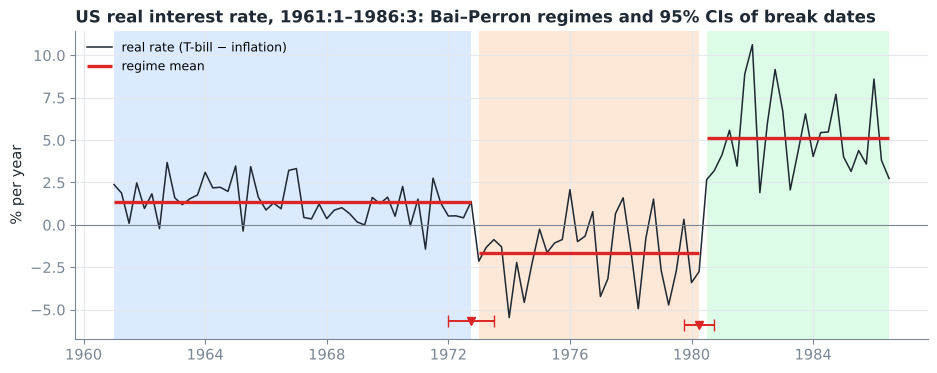

In [10]:
m_sel = bp_rr.selected["sequential"]
ends = bp_rr.ends[m_sel]
means, ses, _ = regime_estimates(y_rr, None, ends, cov="hac")
ci = break_confidence_intervals(y_rr, None, ends, 0.95)
seg_bounds = [0] + ends + [len(y_rr)]
reg_tab = pd.DataFrame({
    "regime": [f"{q_idx[seg_bounds[j]]} – {q_idx[seg_bounds[j + 1] - 1]}" for j in range(len(ends) + 1)],
    "mean real rate, %": means[:, 0].round(2),
    "HAC s.e.": ses[:, 0].round(2)})
print(reg_tab.to_string(index=False))
print("\nBreak dates and 95% CIs (Bai, 1997):")
for e, (lo, hi) in zip(ends, ci):
    print(f"  {q_idx[e - 1]}   [{q_idx[lo]}, {q_idx[hi]}]")
reg_tab.to_csv(RESULTS / "bai_perron_real_rate_1961_1986.csv", index=False)

x_rr = rr_bp.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 4))
P.shade_regimes(ax, x_rr, ends)
ax.plot(x_rr, y_rr, color=P.INK, lw=1.1, label="real rate (T-bill − inflation)")
P.plot_regime_means(ax, x_rr, y_rr, ends, means[:, 0])
for e, (lo, hi) in zip(ends, ci):
    ax.errorbar(x_rr[e - 1], ax.get_ylim()[0] + 0.6, xerr=[[x_rr[e - 1] - x_rr[lo]], [x_rr[hi] - x_rr[e - 1]]],
                fmt="v", color=P.RED, capsize=4, lw=1.4)
ax.axhline(0, color=P.MUTED, lw=0.8)
ax.set_title("US real interest rate, 1961:1–1986:3: Bai–Perron regimes and 95% CIs of break dates")
ax.set_ylabel("% per year"); ax.legend(loc="upper left", fontsize=9)
P.savefig(fig, "05_real_rate_bai_perron")

**The result matches the paper's example:** two breaks — late 1972 and mid-1980 (Bai–Perron report 1972:3 and 1980:3; the one-quarter difference comes from slightly different inflation data, and both of their dates lie inside our 95% CIs).
Financial meaning: three regimes of the real return on the risk-free asset —
1) a moderately positive rate in the 1960s; 2) a **negative** real rate in 1973–1980 (oil shocks, inflation outpacing nominal rates); 3) a sharply positive rate after the "Volcker shock" of 1979–1980. A model estimated over the whole period would give an "average" rate of ≈ 1.6% that did not exist in any regime.

### 5.3. Extending the sample: 1950–2000

In [11]:
bp_rr_full = bai_perron(rr.values, trim=0.15, M=5, cov="hac", index=rr.index.astype(str))
print(bp_rr_full.summary())

Bai-Perron: T=203, q=1, h=30 (trim=0.15), M=5, cov=hac

 k |  sup-F(k) | 5% crit. | break date(s) (global SSR minimum)
---+-----------+----------+-----------------------------------
 1 |    30.82* |     8.43 | ['1980Q2']
 2 |    44.87* |     7.15 | ['1972Q4', '1980Q2']
 3 |    42.07* |     5.92 | ['1972Q4', '1980Q2', '1987Q4']
 4 |    32.82* |     4.99 | ['1958Q2', '1972Q4', '1980Q2', '1987Q4']
 5 |    26.08* |     3.85 | ['1957Q3', '1965Q1', '1972Q4', '1980Q2', '1987Q4']

UDmax =   44.87  (5% crit. 8.76)  *
WDmax =   59.87  (5% crit. 9.80)  *

Sequential test sup-F(l+1|l):
  F(1|0) =    51.03* (5% crit. 8.43)
  F(2|1) =    19.94* (5% crit. 9.85)
  F(3|2) =    19.85* (5% crit. 10.77)
  F(4|3) =    17.28* (5% crit. 11.65)
  F(5|4) =     0.00  (5% crit. 12.26)

 m |    SSR      |   BIC    |   LWZ
 0 |    1686.986 |   2.1437 |   2.1716
 1 |    1260.804 |   1.9048 |   1.9886
 2 |    1135.729 |   1.8527 |   1.9925
 3 |    1023.033 |   1.8005 |   1.9964
 4 |     934.196 |   1.7620 |   2.0141

On the longer sample the 1972:4 and 1980:2 breaks survive, but beyond that the criteria **disagree**: the sequential test and BIC add breaks in the late 1950s and in 1987:4 (4 in total), while LWZ, with its stricter penalty, keeps only one (1980). This directly illustrates the main "limitation" noted in the paper: **the number and dates of breaks are sensitive to the procedure and the sample length**.

---
## 6. S&P 500 volatility regimes and sensitivity to settings

**Volatility** regimes matter for risk management. We compute monthly realised volatility $RV_m = \sqrt{12\sum_{d\in m} r_d^2}$ from daily S&P 500 log returns and look for mean shifts in $\log RV$ (HAC, since volatility is highly persistent).

In [12]:
spx = pd.read_csv(DATA / "sp500_daily_1950_2018.csv", parse_dates=["Date"]).set_index("Date")
ret = np.log(spx["Adj.Close"]).diff().dropna()
rv = np.sqrt((ret ** 2).resample("ME").sum() * 12)
rv = rv[rv.index < "2018-12-01"]          # the last month is incomplete
log_rv = np.log(rv)
y_v = log_rv.values
m_idx = log_rv.index.strftime("%Y-%m")
print(f"Months: {len(y_v)}, {m_idx[0]} – {m_idx[-1]}")

bp_v = bai_perron(y_v, trim=0.10, M=8, cov="hac", index=m_idx)
print(bp_v.summary())

Months: 827, 1950-01 – 2018-11
Bai-Perron: T=827, q=1, h=82 (trim=0.1), M=8, cov=hac

 k |  sup-F(k) | 5% crit. | break date(s) (global SSR minimum)
---+-----------+----------+-----------------------------------
 1 |    46.07* |     8.90 | ['1973-01']
 2 |    26.46* |     7.74 | ['1973-01', '2011-12']
 3 |    22.18* |     6.65 | ['1973-01', '1997-02', '2011-12']
 4 |    20.54* |     5.92 | ['1973-01', '1990-01', '1996-11', '2011-12']
 5 |    18.62* |     5.32 | ['1962-11', '1973-01', '1990-01', '1996-11', '2011-12']
 6 |    28.26* |     4.76 | ['1962-11', '1973-01', '1990-01', '1996-11', '2003-09', '2011-12']
 7 |    26.57* |     4.18 | ['1963-01', '1969-11', '1979-12', '1990-01', '1996-11', '2003-09', '2011-12']
 8 |    22.65* |     3.50 | ['1958-02', '1966-02', '1973-01', '1979-12', '1990-01', '1996-11', '2003-09', '2011-12']

UDmax =   46.07  (5% crit. 9.24)  *
WDmax =   57.61  (5% crit. 10.30)  *

Sequential test sup-F(l+1|l):
  F(1|0) =   120.12* (5% crit. 8.90)
  F(2|1) =    27.6

           regime  regime volatility, % p.a.
1950-01 – 1962-11                       10.2
1962-12 – 1973-01                        8.1
1973-02 – 1990-01                       13.4
1990-02 – 1996-11                       10.2
1996-12 – 2003-09                       18.8
2003-10 – 2011-12                       14.9
2012-01 – 2018-11                       10.6

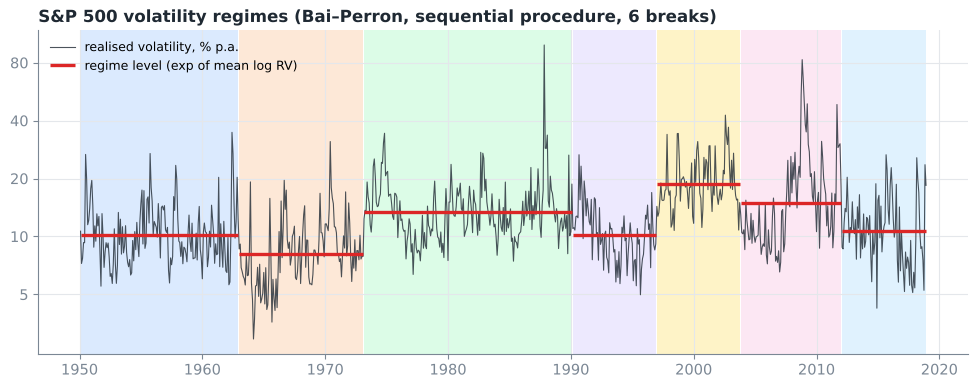

In [13]:
m_v = bp_v.selected["sequential"]
ends_v = bp_v.ends[m_v]
means_v, _, _ = regime_estimates(y_v, None, ends_v)
fig, ax = plt.subplots(figsize=(12, 4.2))
P.shade_regimes(ax, rv.index, ends_v)
ax.plot(rv.index, rv.values * 100, color=P.INK, lw=0.8, alpha=0.8, label="realised volatility, % p.a.")
P.plot_regime_means(ax, rv.index, rv.values, ends_v, np.exp(means_v[:, 0]) * 100,
                    label="regime level (exp of mean log RV)")
ax.set_yscale("log"); ax.minorticks_off(); ax.set_yticks([5, 10, 20, 40, 80], ["5", "10", "20", "40", "80"])
ax.set_title(f"S&P 500 volatility regimes (Bai–Perron, sequential procedure, {m_v} breaks)")
ax.legend(loc="upper left", fontsize=9)
P.savefig(fig, "06_sp500_vol_regimes")
seg_v = [0] + ends_v + [len(y_v)]
print(pd.DataFrame({"regime": [f"{m_idx[seg_v[j]]} – {m_idx[seg_v[j + 1] - 1]}" for j in range(len(ends_v) + 1)],
                    "regime volatility, % p.a.": (np.exp(means_v[:, 0]) * 100).round(1)}).to_string(index=False))

### 6.1. Sensitivity to the trimming ε and the selection criterion

In the section "Bai–Perron tests have revealed the following limitations" the paper claims that the number and location of breaks depend strongly on the type of test and the trimming parameters (citing Dholakia & Sapre, 2011). Let us check this quantitatively.

 ε (trim)  h, months  M  sequential  BIC  LWZ  UDmax signif.                                                     dates (sequential)
     0.05         41  8           8    8    6           True 1962-11, 1966-04, 1973-01, 1991-12, 1996-11, 2003-07, 2007-06, 2011-12
     0.10         82  8           6    6    3           True                   1962-11, 1973-01, 1990-01, 1996-11, 2003-09, 2011-12
     0.15        124  5           3    3    1           True                                              1962-10, 1973-02, 1996-11
     0.20        165  3           2    2    1           True                                                       1973-01, 1996-11
     0.25        206  2           2    2    1           True                                                       1973-01, 1996-11

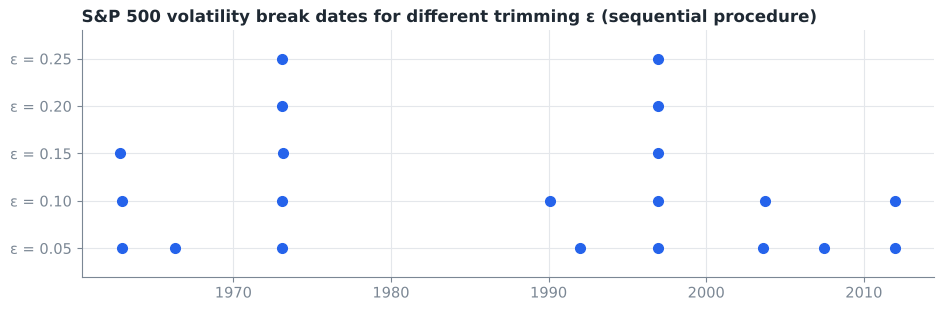

In [14]:
rows = []
for trim in (0.05, 0.10, 0.15, 0.20, 0.25):
    r = bai_perron(y_v, trim=trim, M=8, cov="hac", index=m_idx)
    rows.append({"ε (trim)": trim, "h, months": r.h, "M": r.M,
                 "sequential": r.selected["sequential"], "BIC": r.selected["BIC"], "LWZ": r.selected["LWZ"],
                 "UDmax signif.": r.UDmax > r.crit["UDmax"],
                 "dates (sequential)": ", ".join(r.break_dates(r.selected["sequential"]))})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False))
sens.to_csv(RESULTS / "sensitivity_sp500_vol.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 3.2))
for k, row in enumerate(rows):
    r = bai_perron(y_v, trim=row["ε (trim)"], M=8, cov="hac", index=m_idx)
    for e in r.ends[row["sequential"]]:
        ax.plot(rv.index[e - 1], k, "o", color=P.BLUE, ms=7)
ax.set_yticks(range(len(rows)), [f"ε = {r['ε (trim)']:.2f}" for r in rows])
ax.set_title("S&P 500 volatility break dates for different trimming ε (sequential procedure)")
ax.set_ylim(-0.6, len(rows) - 0.4)
P.savefig(fig, "07_sensitivity_trimming")

**Conclusion.** The "robust" breaks (early 1970s, late 1990s) are found almost always, but the **number** of breaks depends on ε and on the criterion: a small trimming allows short regimes (crisis spikes, 2003–2011), while a large one physically rules out more than $1/ε - 1$ breaks. BIC usually picks more breaks than LWZ (LWZ has a stricter penalty — as the paper says). Practical recommendation: always report results for several values of ε and several criteria, as done here.

---
## 7. Monte Carlo: testing the paper's claims about the properties of the tests

The paper makes several qualitative claims without checking them. We check them by simulation (T = 200):

1. "If the date is known, the Chow test is more powerful" — we compare Chow at the true date, Chow at a wrong date, sup-F and CUSUM.
2. CUSUM is weak against a coefficient shift when the regressor has zero mean.
3. The Chow test has distorted size when error variances differ across regimes (Toyoda, 1974; Schmidt & Sickles, 1977).

Shift in the CONSTANT (mean):
               Chow (true date)  Chow (date off by 40)  sup-F (Andrews)  CUSUM  CUSUM²
shift size δ                                                                         
0.0                      0.044                  0.044            0.040  0.052   0.024
0.2                      0.198                  0.112            0.136  0.080   0.022
0.4                      0.682                  0.332            0.518  0.250   0.050
0.6                      0.964                  0.634            0.898  0.578   0.056
0.8                      0.998                  0.920            0.986  0.854   0.156 

Shift in the SLOPE (beta) with a zero-mean regressor:
               Chow (true date)  Chow (date off by 40)  sup-F (Andrews)  CUSUM  CUSUM²
shift size δ                                                                         
0.0                      0.062                  0.064            0.052  0.048   0.022
0.2                      0.238                  0.11

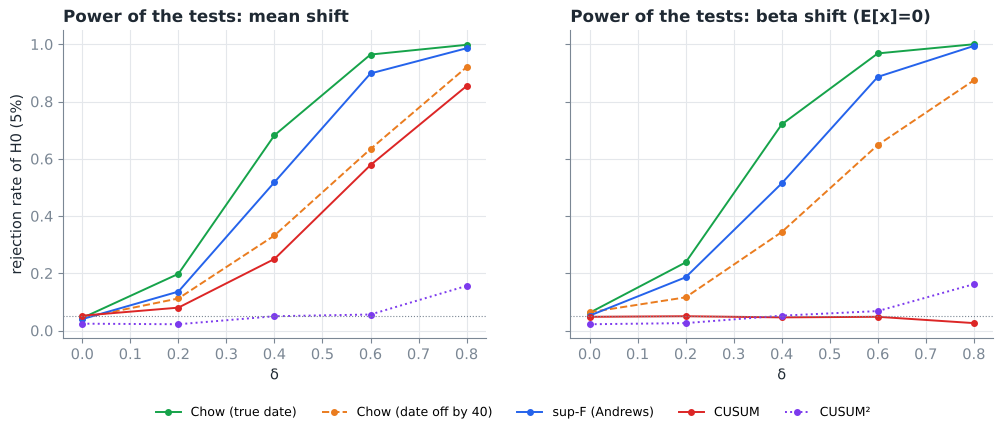

In [15]:
rng = np.random.default_rng(2026)
T_mc, n_rep, true_b = 200, 500, 100

def power_curve(shift_type, deltas):
    out = {k: [] for k in ["Chow (true date)", "Chow (date off by 40)", "sup-F (Andrews)", "CUSUM", "CUSUM²"]}
    for d in deltas:
        rej = {k: 0 for k in out}
        for _ in range(n_rep):
            x = rng.standard_normal(T_mc)
            X = np.column_stack([np.ones(T_mc), x])
            jump = np.r_[np.zeros(true_b), np.ones(T_mc - true_b)] * d
            y = 0.5 + 1.0 * x + (jump if shift_type == "mean" else jump * x) + rng.standard_normal(T_mc)
            rej["Chow (true date)"] += chow_test(y, X, true_b).pvalue < 0.05
            rej["Chow (date off by 40)"] += chow_test(y, X, true_b + 40).pvalue < 0.05
            rej["sup-F (Andrews)"] += sup_f_test(y, X).pvalues["sup"] < 0.05
            rej["CUSUM"] += cusum_test(y, X).reject
            rej["CUSUM²"] += cusumsq_test(y, X).reject
        for k in out:
            out[k].append(rej[k] / n_rep)
    return pd.DataFrame(out, index=pd.Index(deltas, name="shift size δ"))

deltas = [0.0, 0.2, 0.4, 0.6, 0.8]
pw_mean = power_curve("mean", deltas)
pw_slope = power_curve("slope", deltas)
print("Shift in the CONSTANT (mean):\n", pw_mean.round(3).to_string(), "\n")
print("Shift in the SLOPE (beta) with a zero-mean regressor:\n", pw_slope.round(3).to_string())
pw_mean.to_csv(RESULTS / "mc_power_mean_shift.csv"); pw_slope.to_csv(RESULTS / "mc_power_slope_shift.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
styles = {"Chow (true date)": (P.GREEN, "-"), "Chow (date off by 40)": (P.ORANGE, "--"),
          "sup-F (Andrews)": (P.BLUE, "-"), "CUSUM": (P.RED, "-"), "CUSUM²": (P.PURPLE, ":")}
for a, df, ttl in [(ax[0], pw_mean, "mean shift"), (ax[1], pw_slope, "beta shift (E[x]=0)")]:
    for col in df:
        c, ls = styles[col]
        a.plot(df.index, df[col], color=c, ls=ls, marker="o", ms=4, label=col)
    a.axhline(0.05, color=P.MUTED, lw=0.8, ls=":")
    a.set_title(f"Power of the tests: {ttl}"); a.set_xlabel("δ")
ax[0].set_ylabel("rejection rate of H0 (5%)")
h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=5, fontsize=9, bbox_to_anchor=(0.5, -0.12))
P.savefig(fig, "08_mc_power")

**Simulation results.**
* With the true date, Chow is indeed the most powerful test (as the paper claims) — but this is an "oracle". If the date is off by 40 observations, power almost halves (at δ = 0.4: 0.33 vs 0.68), and sup-F, which does not need the date at all, does noticeably better (0.52).
* CUSUM works against a mean shift but has **almost no power against a beta shift** with a centred regressor — which explains our CAPM result in Section 4.

Now the size of the Chow test under heteroskedasticity (H0 of equal coefficients is true; only the error variance changes):

In [16]:
def chow_size(n1, sd2, reps=2000):
    rej_f = rej_w = 0
    for _ in range(reps):
        x = rng.standard_normal(T_mc)
        X = np.column_stack([np.ones(T_mc), x])
        e = np.r_[rng.standard_normal(n1), sd2 * rng.standard_normal(T_mc - n1)]
        y = 0.5 + x + e
        rej_f += chow_test(y, X, n1).pvalue < 0.05
        rej_w += chow_dummy_wald(y, X, n1, lags=0).pvalue < 0.05
    return rej_f / reps, rej_w / reps

rows = []
for n1 in (100, 40, 160):
    for sd2 in (1.0, 3.0):
        f, w = chow_size(n1, sd2)
        rows.append({"n1": n1, "n2": T_mc - n1, "σ2/σ1": sd2, "size Chow F": f, "size Wald (robust)": w})
size_tab = pd.DataFrame(rows)
print(size_tab.to_string(index=False))
size_tab.to_csv(RESULTS / "mc_chow_size_heteroskedasticity.csv", index=False)

 n1  n2  σ2/σ1  size Chow F  size Wald (robust)
100 100    1.0       0.0425              0.0515
100 100    3.0       0.0485              0.0580
 40 160    1.0       0.0585              0.0945
 40 160    3.0       0.0000              0.0655
160  40    1.0       0.0515              0.0840
160  40    3.0       0.3385              0.0905

With equal variances and equal subsamples both tests hold ≈5%. But if the variance is higher in the **shorter** subsample (n1=160, n2=40, σ2/σ1=3), the classical Chow F-test rejects the true H0 in about **a third** of cases instead of 5%; if it is higher in the longer one (n1=40), the test almost never rejects (it loses power). This is the effect described by Toyoda (1974) and Schmidt & Sickles (1977). The robust (White) version keeps the size within 5–9% in all cases (the slight over-rejection is the price of estimating the variance from 40 observations). For financial data with volatility clustering this is not a theoretical nicety but a necessary correction.

---
## 8. Summary

| Method | What it gives | Limitations (from the paper and our calculations) |
|---|---|---|
| Chow | exact F-test at a **known** date | the date is often endogenous; a wrong date leads to false conclusions; sensitive to heteroskedasticity |
| Quandt–Andrews sup-F | no need to know the date of a single break; date estimate = argmax | only one break; non-standard critical values (Andrews, 1993) |
| CUSUM / CUSUM² | simple graphical diagnostic | low power (especially against a beta shift); does not date breaks |
| Bai–Perron | number **and** dates of several breaks, CIs for dates, HAC | sensitive to ε, M and the selection criterion; requires a minimum regime length |

**Main financial findings:** (1) the food industry beta roughly halved in the mid-1990s; (2) the US real interest rate went through three regimes with transitions in 1972–73 and 1980 — the paper's example is reproduced; (3) S&P 500 volatility has clear regimes, but their dating depends on the procedure's settings.

In [17]:
print("Done. Figures are in figures/, tables in results/.")

Done. Figures are in figures/, tables in results/.